# 🛒 E-commerce Data Analysis

### Project Domain: E-commerce Analytics | Data Analysis | Business Analytics

**Objective:** Analyze online shopping data to understand customers, sales and products, clean the real-world data that has missing values, and share simple insights using **only Python**.

**Tools:** Python, NumPy, Pandas, Matplotlib, Seaborn

**Skills:** Data Cleaning & Preprocessing, Missing Value Treatment, Exploratory Data Analysis (EDA), Data Visualization, Business Analytics

## Step 1: Import Libraries & Load the Data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("reports/charts", exist_ok=True)   # charts will be saved here

In [2]:
path = "data/"

customers   = pd.read_csv(path + "customers.csv")
orders      = pd.read_csv(path + "orders.csv")
order_items = pd.read_csv(path + "order_items.csv")
products    = pd.read_csv(path + "products.csv")
sellers     = pd.read_csv(path + "sellers.csv")
payments    = pd.read_csv(path + "payments.csv")

tables = {"customers": customers, "orders": orders, "order_items": order_items,
          "products": products, "sellers": sellers, "payments": payments}

for name, table in tables.items():
    print(name, "->", table.shape)

customers -> (99441, 5)
orders -> (99441, 8)
order_items -> (112650, 7)
products -> (32951, 9)
sellers -> (3095, 4)
payments -> (103886, 5)


In [3]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


## Step 2: Understand the Data
- Check the data types of each table
- Find which tables have missing values

In [4]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [5]:
# Total missing values in every table
for name, table in tables.items():
    print(f"{name:12} missing values: {table.isna().sum().sum()}")

customers    missing values: 0
orders       missing values: 4908
order_items  missing values: 0
products     missing values: 2448
sellers      missing values: 0
payments     missing values: 0


In [6]:
# Which columns have missing values?
print("ORDERS")
print(orders.isna().sum()[orders.isna().sum() > 0])
print()
print("PRODUCTS")
print(products.isna().sum()[products.isna().sum() > 0])

ORDERS


order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

PRODUCTS
product category              610
product_name_length           610
product_description_length    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


**Observation**
- `orders` has missing values in 3 date columns
- `products` has missing values in the category and size/description columns
- All other tables have no missing values

## Step 3: Data Cleaning & Preprocessing

In [7]:
# 1. Fix the column name that has a space
products = products.rename(columns={"product category": "product_category"})

# 2. Make category names clean and in the same format
products["product_category"] = products["product_category"].str.strip().str.lower()

# 3. Convert date columns to datetime format
date_cols = ["order_purchase_timestamp", "order_approved_at",
             "order_delivered_carrier_date", "order_delivered_customer_date",
             "order_estimated_delivery_date"]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

orders[date_cols].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [8]:
# 4. Check duplicate rows in every table
tables = {"customers": customers, "orders": orders, "order_items": order_items,
          "products": products, "sellers": sellers, "payments": payments}

for name, table in tables.items():
    print(f"{name:12} duplicate rows: {table.duplicated().sum()}")

customers    duplicate rows: 0


orders       duplicate rows: 0
order_items  duplicate rows: 0


products     duplicate rows: 0
sellers      duplicate rows: 0
payments     duplicate rows: 0


## Step 4: Missing Value Treatment 🩹

We treat missing values in a simple way:

| Column type | Method used | Why? |
|---|---|---|
| Text (`product_category`) | Fill with `"unknown"` | We cannot guess a category |
| Numbers (size, weight, photos...) | Fill with the **median** | Median is not affected by very big or very small values |
| `order_approved_at` | Fill with the order purchase time | Most orders are approved at the time of purchase |
| Delivery dates | Keep them empty | Order is not delivered yet (or cancelled), so a date does not exist |

In [9]:
# Missing values BEFORE treatment
before = pd.DataFrame({
    "orders": orders.isna().sum(),
    "products": products.isna().sum()
}).fillna(0).astype(int)
before = before[(before["orders"] > 0) | (before["products"] > 0)]
before

,orders,products
order_approved_at,160,0
order_delivered_carrier_date,1783,0
order_delivered_customer_date,2965,0
product_category,0,610
product_description_length,0,610
product_height_cm,0,2
product_length_cm,0,2
product_name_length,0,610
product_photos_qty,0,610
product_weight_g,0,2


### 4.1 Products table

In [10]:
# Text column -> "unknown"
products["product_category"] = products["product_category"].fillna("unknown")

# Number columns -> median
num_cols = ["product_name_length", "product_description_length", "product_photos_qty",
            "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]

for col in num_cols:
    products[col] = products[col].fillna(products[col].median())

products.isna().sum()

product_id                    0
product_category              0
product_name_length           0
product_description_length    0
product_photos_qty            0
product_weight_g              0
product_length_cm             0
product_height_cm             0
product_width_cm              0
dtype: int64

### 4.2 Orders table

In [11]:
# Approval time -> use the purchase time
orders["order_approved_at"] = orders["order_approved_at"].fillna(orders["order_purchase_timestamp"])

# Delivery dates are missing because the order was not delivered.
# Let's confirm this by checking the order status of those rows
no_delivery = orders[orders["order_delivered_customer_date"].isna()]
no_delivery["order_status"].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [12]:
# Instead of inventing dates, we make a clear column that tells if the order was delivered
orders["is_delivered"] = orders["order_delivered_customer_date"].notna()

# Delivery time in days (only possible for delivered orders)
orders["delivery_days"] = (orders["order_delivered_customer_date"]
                           - orders["order_purchase_timestamp"]).dt.days
orders[["order_status", "is_delivered", "delivery_days"]].head()

,order_status,is_delivered,delivery_days
0,delivered,True,8.0
1,delivered,True,13.0
2,delivered,True,9.0
3,delivered,True,13.0
4,delivered,True,2.0


In [13]:
# Missing values AFTER treatment
after = pd.DataFrame({
    "orders": orders.isna().sum(),
    "products": products.isna().sum()
}).fillna(0).astype(int)
after = after.loc[before.index]
after

,orders,products
order_approved_at,0,0
order_delivered_carrier_date,1783,0
order_delivered_customer_date,2965,0
product_category,0,0
product_description_length,0,0
product_height_cm,0,0
product_length_cm,0,0
product_name_length,0,0
product_photos_qty,0,0
product_weight_g,0,0


**Conclusion**
- All missing values in `products` are treated (median for numbers, `unknown` for category)
- `order_approved_at` is treated using the purchase time
- Delivery dates stay empty on purpose, because those orders were never delivered

## Step 5: Join the Tables

All the information is in different tables, so we join them into one table called `sales`.
Cancelled and unavailable orders are removed, because they did not bring any sales.

In [14]:
sales = (order_items
         .merge(products[["product_id", "product_category"]], on="product_id")
         .merge(orders[["order_id", "customer_id", "order_purchase_timestamp", "order_status"]], on="order_id")
         .merge(customers[["customer_id", "customer_unique_id", "customer_city", "customer_state"]], on="customer_id"))

# Remove orders that did not happen
sales = sales[~sales["order_status"].isin(["canceled", "unavailable"])]

# Extra date columns
sales["year"] = sales["order_purchase_timestamp"].dt.year
sales["month"] = sales["order_purchase_timestamp"].dt.month
sales["year_month"] = sales["order_purchase_timestamp"].dt.to_period("M")

print("Shape:", sales.shape)
print("Total product sales:", round(sales["price"].sum(), 2))
sales.head()

Shape: (112101, 17)
Total product sales: 13494400.74


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category,customer_id,order_purchase_timestamp,order_status,customer_unique_id,customer_city,customer_state,year,month,year_month
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool stuff,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,delivered,871766c5855e863f6eccc05f988b23cb,campos dos goytacazes,RJ,2017,9,2017-09
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet shop,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,delivered,eb28e67c4c0b83846050ddfb8a35d051,santa fe do sul,SP,2017,4,2017-04
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,furniture decoration,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,delivered,3818d81c6709e39d06b2738a8d3a2474,para de minas,MG,2018,1,2018-01
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumery,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,delivered,af861d436cfc08b2c2ddefd0ba074622,atibaia,SP,2018,8,2018-08
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,garden tools,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,delivered,64b576fb70d441e8f1b2d7d446e483c5,varzea paulista,SP,2017,2,2017-02


## Step 6: Exploratory Data Analysis (EDA)

### Q1. Where do our customers live?

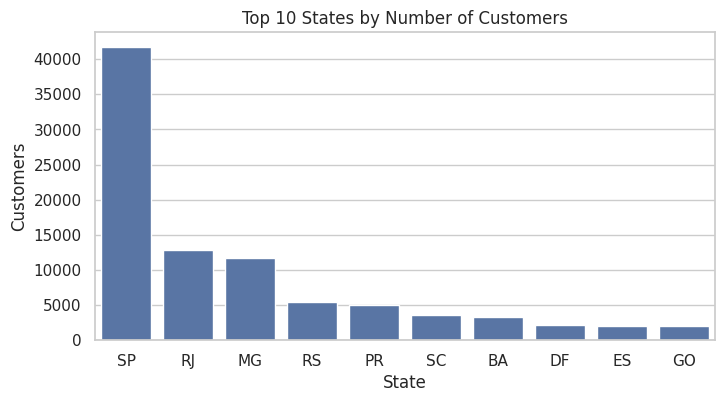

Unique customer cities: 4119
Unique customer states: 27


In [15]:
state_count = customers["customer_state"].value_counts().head(10)

plt.figure(figsize=(8, 4))
sns.barplot(x=state_count.index, y=state_count.values, color="#4C72B0")
plt.title("Top 10 States by Number of Customers")
plt.xlabel("State")
plt.ylabel("Customers")
plt.savefig("reports/charts/customers_by_state.png", bbox_inches="tight")
plt.show()

print("Unique customer cities:", customers["customer_city"].nunique())
print("Unique customer states:", customers["customer_state"].nunique())

In [16]:
state_share = (customers["customer_state"].value_counts(normalize=True) * 100).round(2)
print(state_share.head(3))

customer_state
SP    41.98
RJ    12.92
MG    11.70
Name: proportion, dtype: float64


### Analysis
- Customers come from 27 states and over 4,000 cities
- State **SP** has the most customers (about 42%), then **RJ** (about 13%) and **MG** (about 12%)
### Conclusion
- Almost half of the customers live in just one state, so SP is the most important market

### Q2. How many orders were placed each year?

In [17]:
orders["year"] = orders["order_purchase_timestamp"].dt.year
orders["month"] = orders["order_purchase_timestamp"].dt.month

yearly_orders = orders["year"].value_counts().sort_index()
yearly_orders

year
2016      329
2017    45101
2018    54011
Name: count, dtype: int64

### Analysis
- 2016 has very few orders (the shop was just starting)
- 2017 and 2018 have a big number of orders
### Conclusion
- The shop grew a lot after 2016

### Q3. How did the orders change month by month?

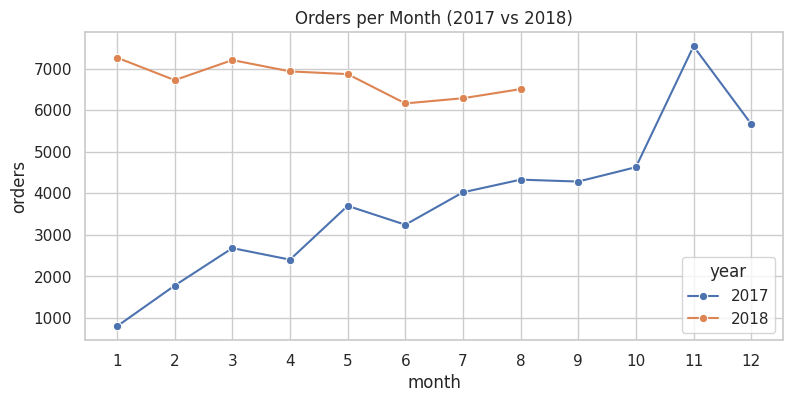

,year,month,orders
10,2017,11,7544
12,2018,1,7269
14,2018,3,7211


In [18]:
# 2016 and the last months of 2018 have very few records, so we look at Jan 2017 - Aug 2018
monthly_orders = (orders[(orders["order_purchase_timestamp"] >= "2017-01-01") &
                         (orders["order_purchase_timestamp"] < "2018-09-01")]
                  .groupby(["year", "month"]).size().reset_index(name="orders"))

plt.figure(figsize=(9, 4))
sns.lineplot(data=monthly_orders, x="month", y="orders", hue="year", marker="o", palette=["#4C72B0", "#DD8452"])
plt.title("Orders per Month (2017 vs 2018)")
plt.xticks(range(1, 13))
plt.savefig("reports/charts/orders_per_month.png", bbox_inches="tight")
plt.show()

monthly_orders.sort_values("orders", ascending=False).head(3)

### Analysis
- Orders go up through 2017 and the highest point comes in November
- 2018 stays at a high level from January to August
### Conclusion
- November is the busiest month (shopping season)

### Q4. Which product categories earn the most?

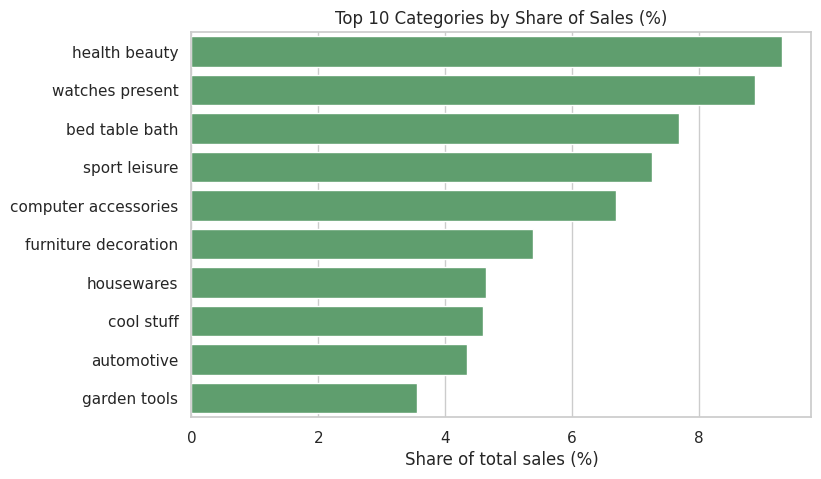

product_category
health beauty           9.31
watches present         8.88
bed table bath          7.68
sport leisure           7.26
computer accessories    6.70
furniture decoration    5.39
housewares              4.65
cool stuff              4.60
automotive              4.35
garden tools            3.56
Name: price, dtype: float64

In [19]:
category_sales = (sales.groupby("product_category")["price"].sum()
                  .sort_values(ascending=False))

# Percentage of total sales
category_percent = (category_sales / category_sales.sum() * 100).round(2)
top10 = category_percent.head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top10.values, y=top10.index, color="#55A868")
plt.title("Top 10 Categories by Share of Sales (%)")
plt.xlabel("Share of total sales (%)")
plt.ylabel("")
plt.savefig("reports/charts/top_categories.png", bbox_inches="tight")
plt.show()

top10

### Analysis
- **Health & beauty** (about 9.3%), **watches & gifts** (about 8.9%) and **bed, table & bath** (about 7.7%) are the top 3 categories
### Conclusion
- Sales are spread over many categories, but these 3 lead the market

### Q5. How do customers pay?

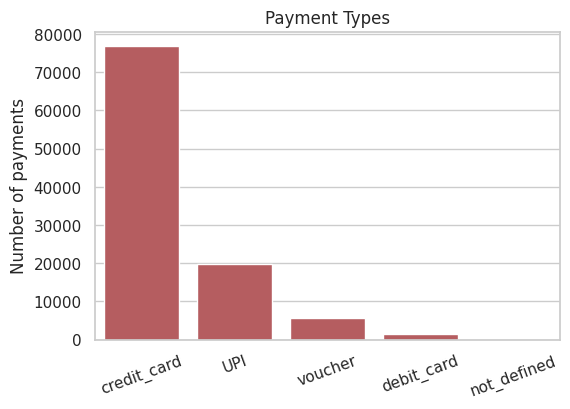

Payments done in installments: 49.42 %
Average payment value: 154.1


In [20]:
payment_type = payments["payment_type"].value_counts()

plt.figure(figsize=(6, 4))
sns.barplot(x=payment_type.index, y=payment_type.values, color="#C44E52")
plt.title("Payment Types")
plt.xlabel("")
plt.ylabel("Number of payments")
plt.xticks(rotation=20)
plt.savefig("reports/charts/payment_types.png", bbox_inches="tight")
plt.show()

# Percentage of payments done in more than 1 installment
installment_percent = (payments["payment_installments"] > 1).mean() * 100
print("Payments done in installments:", round(installment_percent, 2), "%")
print("Average payment value:", round(payments["payment_value"].mean(), 2))

### Analysis
- Credit card is the most used way to pay
- About half of the payments (49%) are split into installments
### Conclusion
- Customers like to pay by card, and many of them prefer to pay in parts

### Q6. Does a higher price mean more purchases?

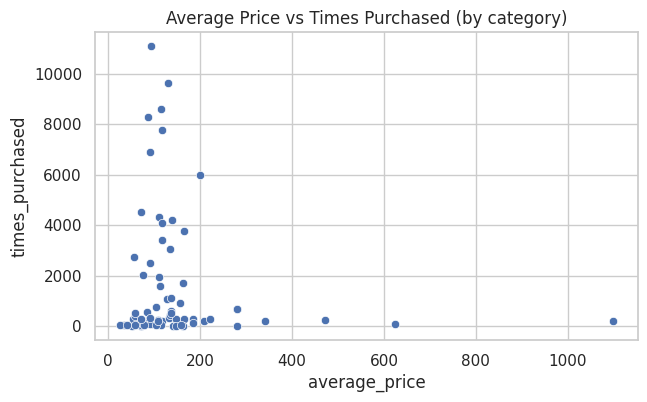

Correlation: -0.106


In [21]:
price_vs_count = sales.groupby("product_category").agg(
    times_purchased=("order_id", "count"),
    average_price=("price", "mean")
).reset_index()

plt.figure(figsize=(7, 4))
sns.scatterplot(data=price_vs_count, x="average_price", y="times_purchased")
plt.title("Average Price vs Times Purchased (by category)")
plt.savefig("reports/charts/price_vs_purchases.png", bbox_inches="tight")
plt.show()

correlation = np.corrcoef(price_vs_count["average_price"], price_vs_count["times_purchased"])[0, 1]
print("Correlation:", round(correlation, 3))

### Analysis
- The correlation is close to zero and slightly negative
### Conclusion
- Price alone does not decide how many times a product is bought

### Q7. Who are our top 5 sellers?

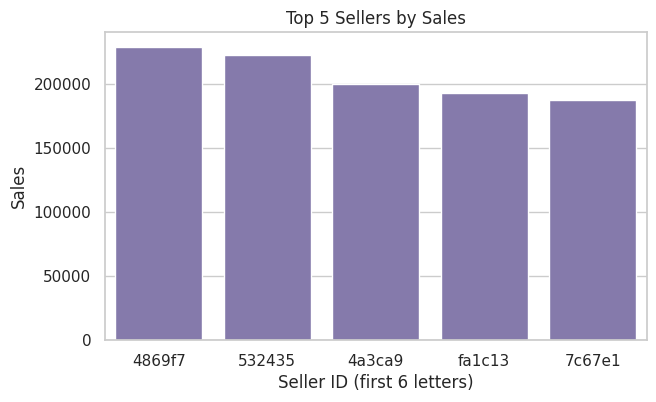

,seller_id,price
0,4869f7,229237.63
1,532435,222776.05
2,4a3ca9,200326.12
3,fa1c13,192842.13
4,7c67e1,187923.89


In [22]:
seller_sales = (sales.groupby("seller_id")["price"].sum()
                .sort_values(ascending=False).head(5).reset_index())
seller_sales["seller_id"] = seller_sales["seller_id"].str[:6]   # short id to read easily

plt.figure(figsize=(7, 4))
sns.barplot(data=seller_sales, x="seller_id", y="price", color="#8172B3")
plt.title("Top 5 Sellers by Sales")
plt.xlabel("Seller ID (first 6 letters)")
plt.ylabel("Sales")
plt.savefig("reports/charts/top_sellers.png", bbox_inches="tight")
plt.show()

seller_sales

In [23]:
# How much of the sales do the top 5 sellers bring?
total_sales = sales["price"].sum()
top5_share = (sales.groupby("seller_id")["price"].sum().nlargest(5).sum() / total_sales * 100)
print("Top 5 sellers bring", round(top5_share, 2), "% of total sales out of", sales["seller_id"].nunique(), "sellers")

Top 5 sellers bring 7.66 % of total sales out of 3053 sellers


### Conclusion
- Sales are spread over more than 3,000 sellers, the top 5 together bring only about 8%

### Q8. How did sales grow over time?

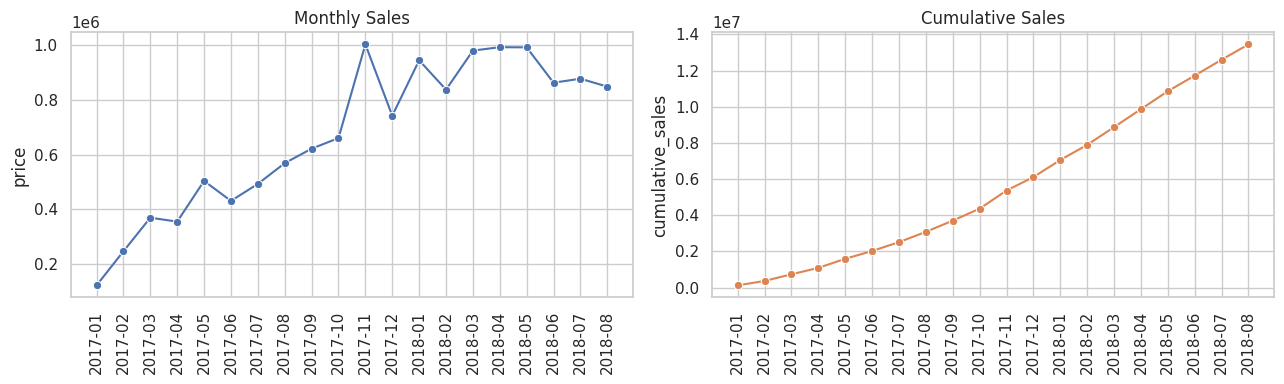

In [24]:
monthly_sales = (sales[(sales["order_purchase_timestamp"] >= "2017-01-01") &
                       (sales["order_purchase_timestamp"] < "2018-09-01")]
                 .groupby("year_month")["price"].sum().reset_index())
monthly_sales["year_month"] = monthly_sales["year_month"].astype(str)
monthly_sales["cumulative_sales"] = monthly_sales["price"].cumsum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.lineplot(data=monthly_sales, x="year_month", y="price", marker="o", ax=axes[0], color="#4C72B0")
axes[0].set_title("Monthly Sales")
axes[0].tick_params(axis="x", rotation=90)
axes[0].set_xlabel("")

sns.lineplot(data=monthly_sales, x="year_month", y="cumulative_sales", marker="o", ax=axes[1], color="#DD8452")
axes[1].set_title("Cumulative Sales")
axes[1].tick_params(axis="x", rotation=90)
axes[1].set_xlabel("")

plt.tight_layout()
plt.savefig("reports/charts/sales_growth.png", bbox_inches="tight")
plt.show()

In [25]:
# Fair comparison: same months (Jan - Aug) of 2017 and 2018
jan_aug = sales[(sales["month"] <= 8) & (sales["year"].isin([2017, 2018]))]
compare = jan_aug.groupby("year")["price"].sum()
growth = (compare[2018] - compare[2017]) / compare[2017] * 100

print(compare.round(2))
print("Sales growth (Jan-Aug 2018 vs Jan-Aug 2017):", round(growth, 2), "%")

year
2017    3080850.81
2018    7341037.41
Name: price, dtype: float64
Sales growth (Jan-Aug 2018 vs Jan-Aug 2017): 138.28 %


### Analysis
- Monthly sales rise through 2017, jump in November 2017, and then stay high in 2018
- The cumulative line keeps going up because new sales are added every month
- Jan-Aug 2018 sales are about 138% higher than Jan-Aug 2017
### Conclusion
- The business is growing strongly

### Q9. How fast are orders delivered?

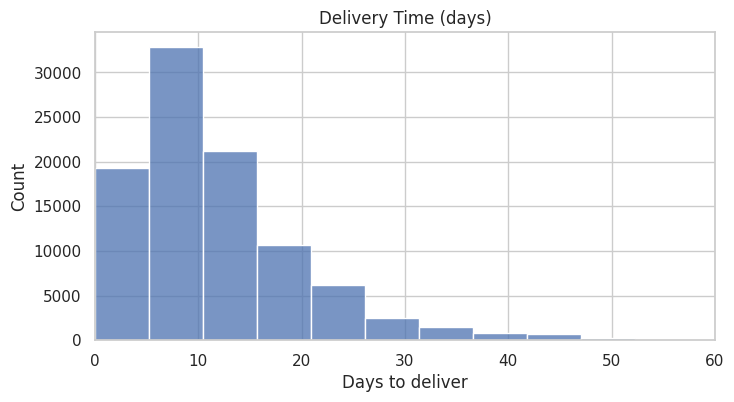

Average delivery time: 12.1 days
Median delivery time: 10.0 days


In [26]:
delivered = orders[orders["is_delivered"]]

plt.figure(figsize=(8, 4))
sns.histplot(delivered["delivery_days"], bins=40, color="#4C72B0")
plt.xlim(0, 60)
plt.title("Delivery Time (days)")
plt.xlabel("Days to deliver")
plt.savefig("reports/charts/delivery_days.png", bbox_inches="tight")
plt.show()

print("Average delivery time:", round(delivered["delivery_days"].mean(), 1), "days")
print("Median delivery time:", delivered["delivery_days"].median(), "days")

### Conclusion
- Most orders reach the customer in about 2 weeks or less

### Q10. How many customers buy again?

In [27]:
# customer_unique_id is the real customer (customer_id changes with every order)
orders_per_customer = (orders.merge(customers[["customer_id", "customer_unique_id"]], on="customer_id")
                       .groupby("customer_unique_id").size())

repeat_percent = (orders_per_customer > 1).mean() * 100
print("Total customers:", len(orders_per_customer))
print("Customers who bought more than once:", round(repeat_percent, 2), "%")

Total customers: 96096
Customers who bought more than once: 3.12 %


### Conclusion
- Very few customers come back for a second order, so there is a big chance to improve customer loyalty

### Q11. Who are the top 5 customers by spending?

In [28]:
top_customers = (sales.groupby("customer_unique_id")["price"].sum()
                 .sort_values(ascending=False).head(5).reset_index())
top_customers["customer_unique_id"] = top_customers["customer_unique_id"].str[:6]
top_customers

,customer_unique_id,price
0,0a0a92,13440.0
1,da122d,7388.0
2,763c8b,7160.0
3,dc4802,6735.0
4,459bef,6729.0


### Q12. Which numbers are connected with each other?

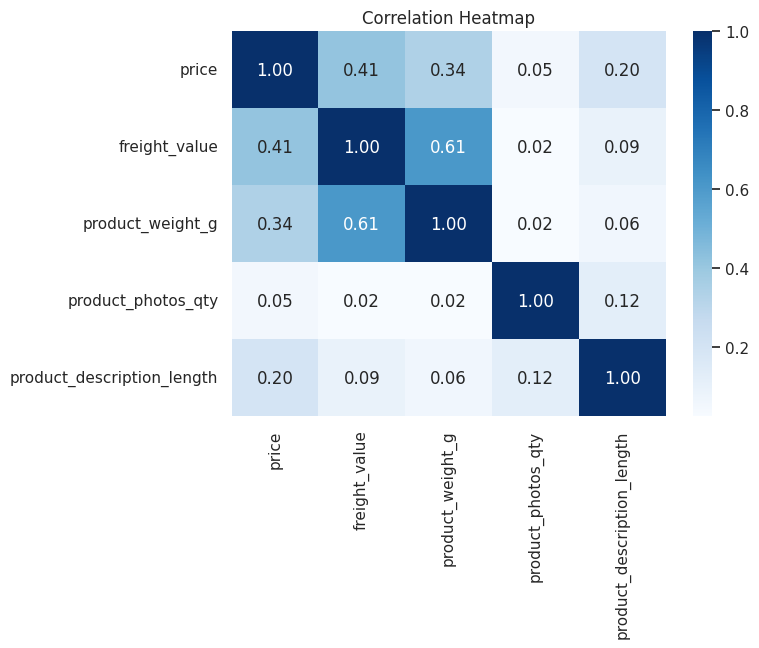

In [29]:
item_details = order_items.merge(products, on="product_id")
corr = item_details[["price", "freight_value", "product_weight_g",
                     "product_photos_qty", "product_description_length"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="Blues", fmt=".2f")
plt.title("Correlation Heatmap")
plt.savefig("reports/charts/correlation_heatmap.png", bbox_inches="tight")
plt.show()

### Analysis
- Weight and freight (delivery) cost have the strongest link (0.61)
- Price is also moderately linked with freight cost (0.41) and weight (0.34)
### Conclusion
- Heavier products cost more to deliver

## Step 7: Save the Cleaned Data & Reports

We save two things as separate CSV files:
- `data/` - the original data files and the cleaned data files (ending with `_cleaned`)
- `reports/` - the results of our analysis

In [30]:
os.makedirs("reports", exist_ok=True)

# ---------- 1. Cleaned data files ----------
clean_tables = {"customers": customers, "orders": orders.drop(columns=["year", "month"]),
                "order_items": order_items, "products": products, "sellers": sellers,
                "payments": payments}

for name, table in clean_tables.items():
    table.to_csv(f"data/{name}_cleaned.csv", index=False)

# the joined table used for the sales analysis
sales[["order_id", "product_id", "seller_id", "product_category", "price", "freight_value",
       "customer_unique_id", "customer_city", "customer_state",
       "order_purchase_timestamp", "order_status", "year", "month"]]     .to_csv("data/sales_joined_cleaned.csv", index=False)
print("Cleaned data files saved:", len(clean_tables) + 1)

Cleaned data files saved: 7


In [31]:
# ---------- 2. Report files ----------

# Missing values report (before and after treatment)
missing_report = before.add_suffix("_before").join(after.add_suffix("_after"))
missing_report.index.name = "column"
missing_report.to_csv("reports/missing_values_report.csv")

# Customers by state
customers["customer_state"].value_counts().rename_axis("state").reset_index(name="customers")     .to_csv("reports/customers_by_state.csv", index=False)

# Orders per year
yearly_orders.rename_axis("year").reset_index(name="orders").to_csv("reports/orders_per_year.csv", index=False)

# Orders per month (Jan 2017 - Aug 2018)
monthly_orders.to_csv("reports/orders_per_month.csv", index=False)

# Sales and share of each category
pd.DataFrame({"sales": category_sales.round(2), "share_percent": category_percent})     .rename_axis("product_category").reset_index().to_csv("reports/category_sales.csv", index=False)

# Payment types
payments.groupby("payment_type").agg(payments=("order_id", "count"),
                                     total_value=("payment_value", "sum")).round(2)     .reset_index().to_csv("reports/payment_types.csv", index=False)

# Monthly and cumulative sales
monthly_sales.round(2).to_csv("reports/monthly_sales.csv", index=False)

# Top 10 sellers (full seller id)
sales.groupby("seller_id")["price"].sum().nlargest(10).round(2)     .reset_index(name="sales").to_csv("reports/top_10_sellers.csv", index=False)

# Top 10 customers by spending (full customer id)
sales.groupby("customer_unique_id")["price"].sum().nlargest(10).round(2)     .reset_index(name="spending").to_csv("reports/top_10_customers.csv", index=False)

# Price vs times purchased (by category)
price_vs_count.round(2).to_csv("reports/price_vs_purchases.csv", index=False)

In [32]:
# Key numbers summary
summary = pd.DataFrame({
    "metric": ["Total orders", "Total customers", "Total sellers", "Total product sales",
               "Top state (share of customers %)", "Top category (share of sales %)",
               "Payments in installments (%)", "Price vs purchases correlation",
               "Sales growth Jan-Aug 2018 vs 2017 (%)", "Average delivery time (days)",
               "Customers who bought more than once (%)"],
    "value": [len(orders), len(orders_per_customer), sales["seller_id"].nunique(),
              round(sales["price"].sum(), 2), round(state_share.iloc[0], 2),
              round(category_percent.iloc[0], 2), round(installment_percent, 2),
              round(correlation, 3), round(growth, 2),
              round(delivered["delivery_days"].mean(), 1), round(repeat_percent, 2)]
})
summary.to_csv("reports/key_summary.csv", index=False)
summary

,metric,value
0,Total orders,9.944100e+04
1,Total customers,9.609600e+04
2,Total sellers,3.053000e+03
3,Total product sales,1.349440e+07
4,Top state (share of customers %),4.198000e+01
5,Top category (share of sales %),9.310000e+00
6,Payments in installments (%),4.942000e+01
7,Price vs purchases correlation,-1.060000e-01
8,Sales growth Jan-Aug 2018 vs 2017 (%),1.382800e+02
9,Average delivery time (days),1.210000e+01


## Key Business Insights (Analytics Outcome)

- 🏙️ About 42% of customers live in one state (SP), so it is the biggest market
- 🛍️ Health & beauty, watches & gifts and bed/table/bath are the top 3 categories by sales
- 💳 Credit card is the most used payment type, and about half of the payments are in installments
- 💰 Price alone does not decide how often a product is bought (correlation about -0.11)
- 📈 Sales in Jan-Aug 2018 are about 138% higher than in Jan-Aug 2017
- 🚚 Orders take about 12 days on average to be delivered (median 10 days)
- 🔁 Only about 3% of customers buy more than once, so customer loyalty can be improved
- 🏪 Sales are spread over 3,000+ sellers, the top 5 bring only about 8%

## Final Conclusion

- This project turned raw e-commerce data with missing values into **clean, structured and insight-driven analytics** using only Python.
- By applying data cleaning, missing value treatment, EDA and visualization, we found which categories earn the most, how customers pay, how fast orders arrive and how sales grow.
- These insights can help online shops and sellers make better business decisions.